# Figure 4 — Solar PV exports comparision for Netherlands and Niue

**Plot one**  Total solar PV export value (USD) from China to the Netherlands and Niue, including Panels, Cells, and Wafers. A logarithmic scale is used to show the large difference between the two countries.

**Plot two** Percentage composition of China's solar PV exports to the Netherlands and Niue by number of items, including Panels, Cells, and Wafers. A percentage bar chart is used to compare the product distribution between the two countries.

# 1. Ranking and selecting countries

In [29]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("https://raw.githubusercontent.com/Amyzzz17/ZhengWangZhouLi/main/data/Raw/mart_solar_exports_full_release_monthly.csv")
countries = df[df["Area type"] == "Country or economy"]
country_total = (
    countries.groupby("Area")["Amount (USD)"]
    .sum()
    .sort_values(ascending=False)
)

print("Country with highest total export value:")
print(country_total.head(1))

print("\nCountry with lowest total export value:")
print(country_total.tail(1))

Country with highest total export value:
Area
Netherlands    4.265772e+10
Name: Amount (USD), dtype: float64

Country with lowest total export value:
Area
Niue    494.0
Name: Amount (USD), dtype: float64


# 2. Total export value comparision

**Question:** How different are China's solar PV export values to the Netherlands and Niue?

**Pattern:** The Netherlands has a much higher total export value ($42.66 billion) than Niue ($494), showing a significant difference in market size.

**Units:** Total export value in USD, displayed on a logarithmic scale.

**Limitation:** The comparison does not account for differences in population, economic size, or possible re-exports.

**Preliminary finding:** The Netherlands is a much larger destination for China's solar PV exports, while Niue represents a very small market in this dataset.

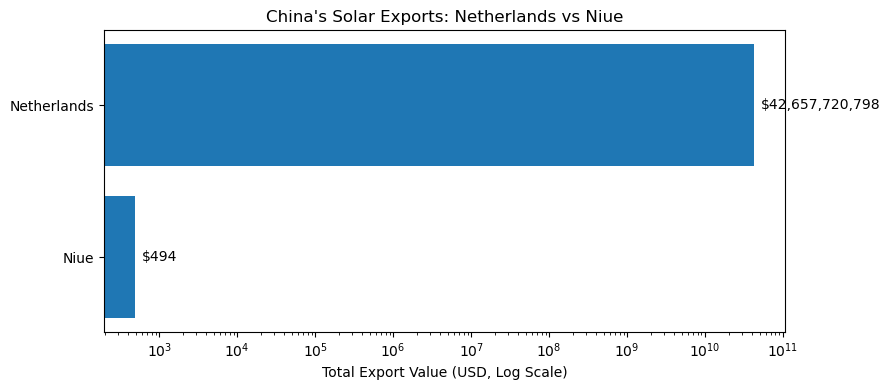

In [30]:
countries = ["Netherlands", "Niue"]

total_exports = (
    df[df["Area"].isin(countries)]
    .groupby("Area")["Amount (USD)"]
    .sum()
    .reindex(countries)
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(total_exports.index, total_exports.values)
ax.set_xscale("log")
ax.invert_yaxis()

ax.set_title("China's Solar Exports: Netherlands vs Niue")
ax.set_xlabel("Total Export Value (USD, Log Scale)")

for i, value in enumerate(total_exports.values):
    ax.annotate(
        f"${value:,.0f}",
        (value, i),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.tight_layout()
plt.show()


# 3. Commodity composition comparision

**Question:** How does the composition of China's solar PV exports differ between the Netherlands and Niue?

**Pattern:** Panels dominate exports to both countries. The Netherlands also receives Cells (5.38%) and Wafers (0.16%), while Niue only receives Panels.

**Units:** Percentage of total exported items for each country.

**Limitation:** The chart shows product proportions rather than actual export quantities or values. Different product types may also have different counting units.

**Preliminary finding:** Panels are the main exported product for both countries, but the Netherlands has a more diverse export composition than Niue.

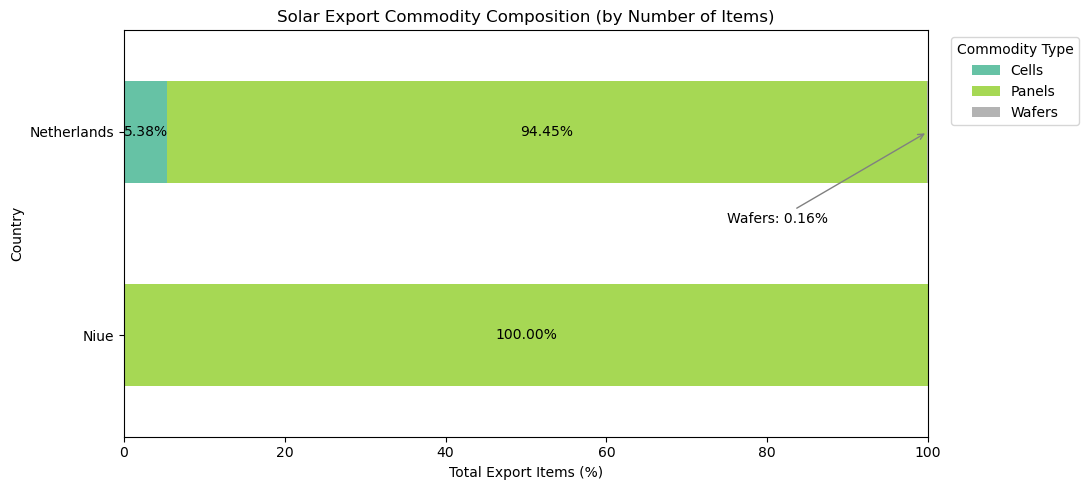

Commodity type  Cells  Panels  Wafers
Area                                 
Netherlands      5.38   94.45    0.16
Niue             0.00  100.00    0.00


In [32]:
countries = ["Netherlands", "Niue"]

data = df[df["Area"].isin(countries)]
items = data.pivot_table(
    index="Area",
    columns="Commodity type",
    values="Amount (items)",
    aggfunc="sum",
    fill_value=0
)
items_pct = items.div(items.sum(axis=1), axis=0) * 100
items_pct = items_pct.reindex(
    index=countries,
    columns=["Cells", "Panels", "Wafers"],
    fill_value=0
)
ax = items_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 5),
    color=["#66c2a5", "#a6d854", "#b3b3b3"],
    width=0.5
)

plt.title("Solar Export Commodity Composition (by Number of Items)")
plt.xlabel("Total Export Items (%)")
plt.ylabel("Country")
plt.xlim(0, 100)
plt.legend(title="Commodity Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.gca().invert_yaxis()

for container in ax.containers:
    labels = [
        f"{bar.get_width():.2f}%" if bar.get_width() >= 5 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center")

# Highlight the small Wafer share in Netherlands
wafer_pct = items_pct.loc["Netherlands", "Wafers"]

ax.annotate(
    f"Wafers: {wafer_pct:.2f}%",
    xy=(100 - wafer_pct / 2, 0),
    xytext=(75, 0.45),
    arrowprops=dict(arrowstyle="->", color="gray"),
    fontsize=10,
    color="black"
)
plt.tight_layout()
plt.show()

print(items_pct.round(2))